In [1]:
import astropy.units as un
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
#t_o = January 27, 1982
#mjd = 44996
#jd = 2444996.5000000

v1370 = pd.read_csv('v1370aql_strope.dat', delim_whitespace = True, header = 0, engine='python')

jd = v1370['JD']
vmag = v1370['Vmag']
err = v1370['Verr']

/var/folders/xv/dvsld6lx4xs_nbgh_qcl11d00000gn/T/ipykernel_4829/1939072472.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  v1370 = pd.read_csv('v1370aql_strope.dat', delim_whitespace = True, header = 0, engine='python')


In [3]:
#jd to date 
#jd t_0 = 55265

def JD_to_date(JD, first):
    days = []
    for i in range(len(JD)):
        days.append(float(JD[i]) - first)
    return(days)

opticaldays = np.array(JD_to_date(jd,2444996.5000000))

In [4]:
v1370_radio = pd.read_csv('V1370_Aql_Radio.txt', delim_whitespace = True, header = 0, engine='python')

mjd = v1370_radio['MJD']
day = v1370_radio['day']
freq = v1370_radio['freq']
flux = v1370_radio['flux']
err = v1370_radio['err']

/var/folders/xv/dvsld6lx4xs_nbgh_qcl11d00000gn/T/ipykernel_4829/1876347694.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  v1370_radio = pd.read_csv('V1370_Aql_Radio.txt', delim_whitespace = True, header = 0, engine='python')


In [5]:
#Sort data by freq and non detections 

A = np.logical_and(freq>= 1, freq<= 1.5) 
L_AC = np.where(np.logical_and(A, flux > 3*err)) 
L_nac = np.where(np.logical_and(A, flux < 3*err))

freq_LAC = np.ravel([freq[i] for i in L_AC])
flux_LAC = np.ravel([flux[i] for i in L_AC])
err_LAC  = np.ravel([err[i] for i in L_AC])
date_LAC = np.ravel([day[i] for i in L_AC])

nflux_LAC = np.ravel([flux[i] + err[i]*3 for i in L_nac])
ndate_LAC = np.ravel([day[i] for i in L_nac])


###############################################################
B = np.logical_and(freq>= 1.5, freq<= 2)
L_BD = np.where(np.logical_and(B, flux > 3*err)) 
L_nbd = np.where(np.logical_and(B, flux < 3*err))

freq_LBD = np.ravel([freq[i] for i in L_BD])
flux_LBD = np.ravel([flux[i] for i in L_BD])
err_LBD  = np.ravel([err[i] for i in L_BD])
date_LBD = np.ravel([day[i] for i in L_BD])

nflux_LBD = np.ravel([flux[i] + err[i]*3 for i in L_nbd])
ndate_LBD = np.ravel([day[i] for i in L_nbd])


###############################################################
C = np.logical_and(freq>= 3, freq<= 6)
C_AC = np.where(np.logical_and(C, flux > 3*err)) 
C_nac = np.where(np.logical_and(C, flux < 3*err))

freq_CAC = np.ravel([freq[i] for i in C_AC])
flux_CAC = np.ravel([flux[i] for i in C_AC])
err_CAC  = np.ravel([err[i] for i in C_AC])
date_CAC = np.ravel([day[i] for i in C_AC])

nflux_CAC = np.ravel([flux[i] + err[i]*3 for i in C_nac])
ndate_CAC = np.ravel([day[i] for i in C_nac])


In [6]:
def quad(err,freq,flux):
    quad_er = []

    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            quad_er.append(p1)
        
        else: 
            p2 = np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            quad_er.append(p2)
            
        
    return(quad_er)  

In [7]:
#Error in Quadrature

quad_Lac = quad(err_LAC,freq_LAC, flux_LAC)  
quad_Lbd = quad(err_LBD,freq_LBD, flux_LBD)   
quad_Cac = quad(err_CAC,freq_CAC, flux_CAC)


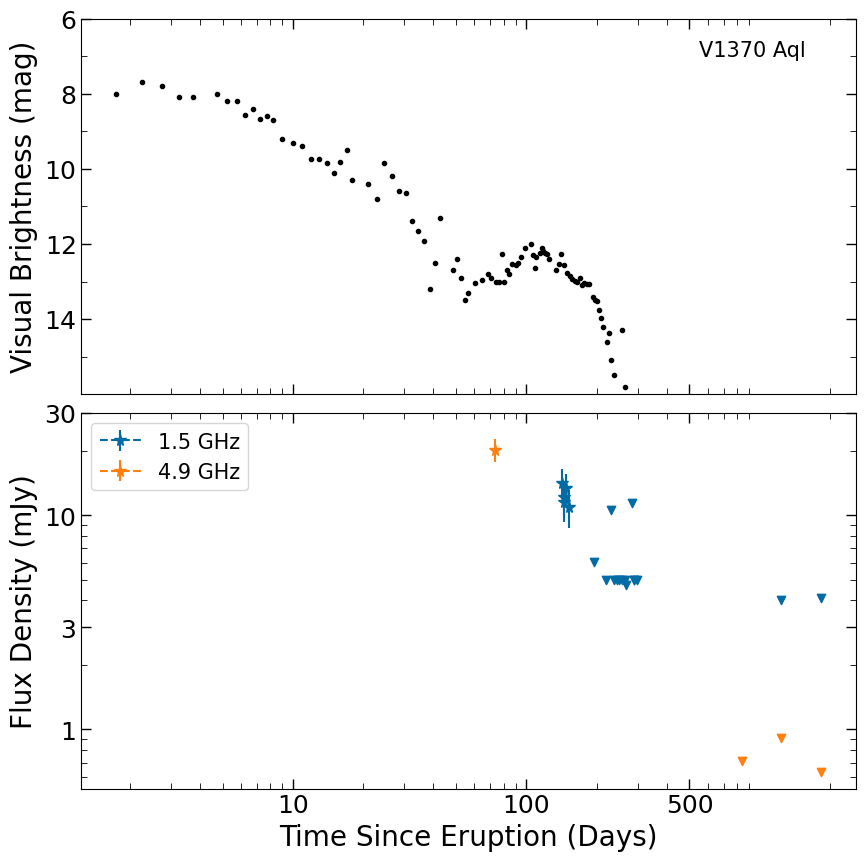

In [8]:
plt.style.use('tableau-colorblind10')
#plt.style.use('dark_background')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(2, 1, figsize=(10, 10), sharey=False, sharex = True)#, constrained_layout=True)


#first the visual
axs[0].scatter(opticaldays, vmag, marker = '.', color = 'black')
axs[0].annotate('V1370 Aql',(550,7), fontsize=15)

axs[0].set_xscale('log')
#axs[0].set_yscale('log')

axs[0].set_ylabel('Visual Brightness (mag)',fontsize =20)

axs[0].set_yticks([6,8,10,12,14], labels = [r'$6$',r'$8$',r'$10$', r'$12$', r'$14$'], fontsize = 18)
axs[0].set_ylim(6,16)
axs[0].invert_yaxis()
axs[0].tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2))  # 2 minor intervals between major ticks
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


#now the radio
axs[1].set_ylabel('Flux Density (mJy)',fontsize=20)
axs[1].set_xlabel('Time Since Eruption (Days)', fontsize=20)
axs[1].set_xscale('log')
axs[1].set_yscale('log')



axs[1].errorbar(date_LAC, flux_LAC, yerr=quad_Lac, linestyle ='--', fmt = '*' , markersize = 8.5, label='1.5 GHz')
axs[1].errorbar(date_CAC, flux_CAC, yerr=quad_Cac, linestyle ='--', fmt = '*', markersize = 8.5, label='4.9 GHz')


axs[1].scatter(ndate_LAC, nflux_LAC, marker = 'v')
axs[1].scatter(ndate_CAC, nflux_CAC, marker = 'v')


axs[1].legend(fontsize=15, loc='upper left')

axs[1].set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)
axs[1].set_yticks([1,3,10,30], labels = [r'$1$',r'$3$',r'$10$',r'$30$'], fontsize = 18)

axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)


fig.subplots_adjust(hspace=0.05)
plt.savefig("V1370Aql_RadioOptical_lightcurves.png")
plt.show();